Cohort and Tunnel analysis

In [1]:
# Re-authenticate — required at the start of every new Colab notebook session
from google.colab import auth
auth.authenticate_user()
print("Authenticated.")

from google.cloud import bigquery
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'

PROJECT_ID = 'cloudiq-analytics'
DATASET    = 'bigquery-public-data.thelook_ecommerce'

client    = bigquery.Client(project=PROJECT_ID)
FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)

def run_query(sql):
    return client.query(sql).to_dataframe()

print("BigQuery client ready.")


Authenticated.
BigQuery client ready.


Cohort analysis: build the retention matrix in BigQuery

In [2]:
print("=" * 65)
print("SECTION 1: COHORT RETENTION ANALYSIS")
print("=" * 65)
print("""
Cohort analysis groups customers by the month they first purchased
and tracks what percentage return to buy again in subsequent months.

This reveals:
  - How quickly new customers churn after first purchase
  - Whether retention is improving or declining across acquisition cohorts
  - Which cohort months produce the most loyal customers

All logic runs as a single BigQuery SQL query using window functions.
No Python needed for the heavy lifting — BigQuery does it at scale.
""")

cohort_sql = f"""
WITH first_orders AS (
    -- Step 1: find each customer's first purchase month
    SELECT
        user_id,
        DATE_TRUNC(MIN(created_at), MONTH) AS cohort_month
    FROM `{DATASET}.orders`
    WHERE status NOT IN ('Cancelled')
    GROUP BY user_id
),
order_periods AS (
    -- Step 2: for every subsequent order, calculate months since first purchase
    SELECT
        fo.user_id,
        fo.cohort_month,
        DATE_DIFF(
            DATE_TRUNC(DATE(o.created_at), MONTH),
            DATE(fo.cohort_month),
            MONTH
        ) AS period_number
    FROM first_orders fo
    JOIN `{DATASET}.orders` o ON fo.user_id = o.user_id
    WHERE o.status NOT IN ('Cancelled')
),
cohort_sizes AS (
    -- Step 3: how many customers in each cohort (period 0 = everyone)
    SELECT
        cohort_month,
        COUNT(DISTINCT user_id) AS cohort_size
    FROM order_periods
    WHERE period_number = 0
    GROUP BY cohort_month
),
cohort_retention AS (
    -- Step 4: how many returned in each period
    SELECT
        op.cohort_month,
        op.period_number,
        COUNT(DISTINCT op.user_id) AS retained_users
    FROM order_periods op
    GROUP BY 1, 2
)
-- Step 5: calculate retention rate
SELECT
    cr.cohort_month,
    cr.period_number,
    cr.retained_users,
    cs.cohort_size,
    ROUND(cr.retained_users / cs.cohort_size * 100, 2) AS retention_rate
FROM cohort_retention cr
JOIN cohort_sizes cs ON cr.cohort_month = cs.cohort_month
ORDER BY 1, 2
"""

cohort_df = run_query(cohort_sql)
cohort_df['cohort_month'] = pd.to_datetime(cohort_df['cohort_month'])
print(f"Query returned {len(cohort_df):,} rows")
print(f"Cohorts: {cohort_df['cohort_month'].nunique()}")
print(f"Max period: {cohort_df['period_number'].max()} months")


SECTION 1: COHORT RETENTION ANALYSIS

Cohort analysis groups customers by the month they first purchased
and tracks what percentage return to buy again in subsequent months.

This reveals:
  - How quickly new customers churn after first purchase
  - Whether retention is improving or declining across acquisition cohorts
  - Which cohort months produce the most loyal customers

All logic runs as a single BigQuery SQL query using window functions.
No Python needed for the heavy lifting — BigQuery does it at scale.

Query returned 3,754 rows
Cohorts: 94
Max period: 90 months


Build and visualise the retention heatmap

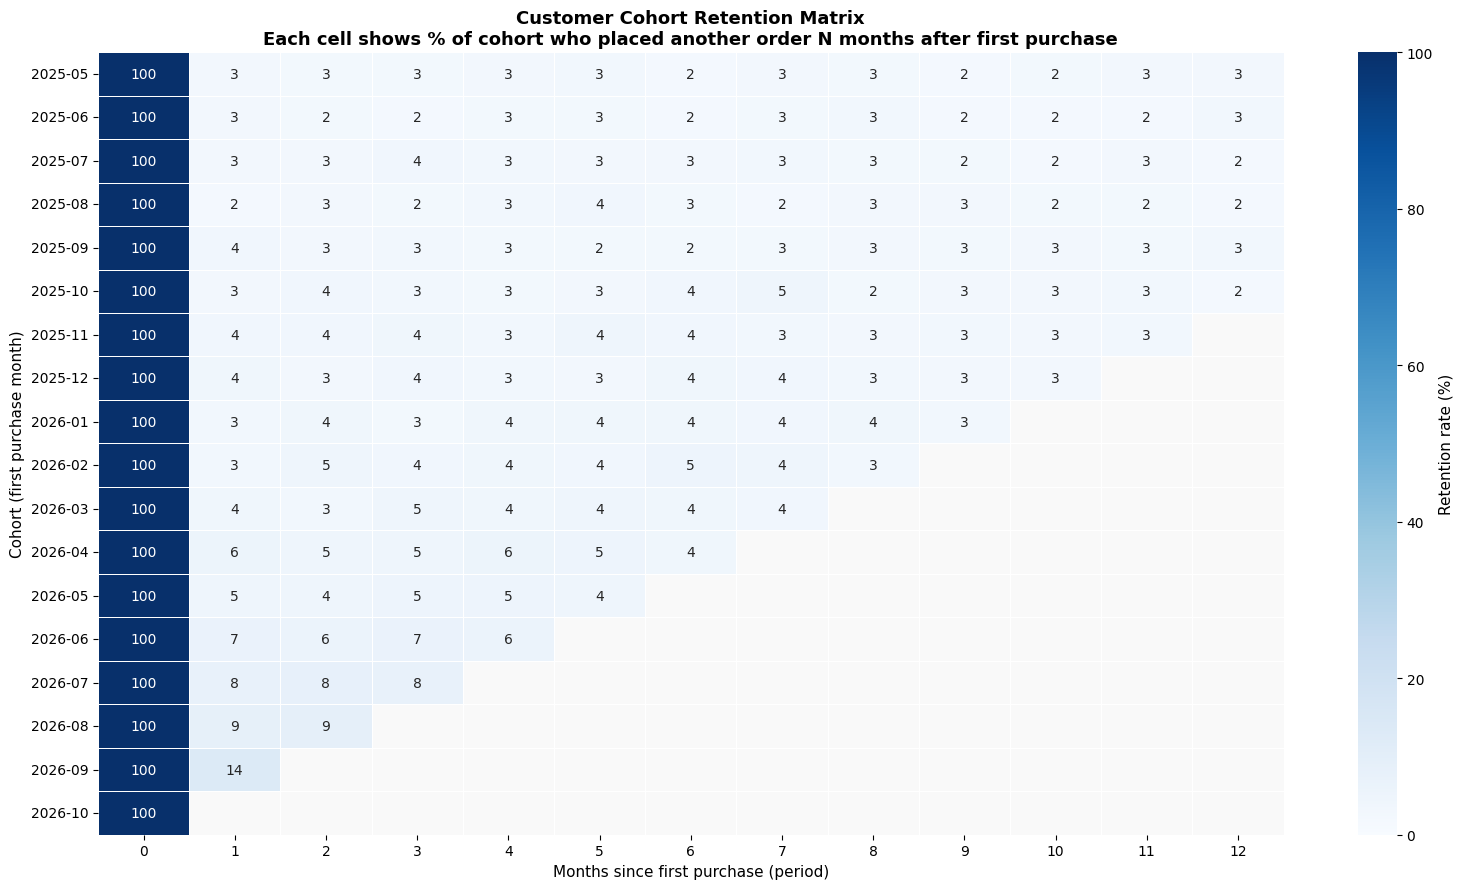

Saved: cohort_retention.csv


In [3]:
# Pivot into cohort × period matrix
retention_matrix = cohort_df.pivot_table(
    index='cohort_month',
    columns='period_number',
    values='retention_rate'
)
retention_matrix.index = retention_matrix.index.strftime('%Y-%m')

# Keep only the first 12 periods and last 18 cohorts for readability
retention_matrix = retention_matrix.iloc[-18:, :13]

fig, ax = plt.subplots(figsize=(16, 9))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt='.0f',
    cmap='Blues',
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    cbar_kws={'label': 'Retention rate (%)'},
    vmin=0,
    vmax=retention_matrix[0].max(),
)

ax.set_title('Customer Cohort Retention Matrix\n'
             'Each cell shows % of cohort who placed another order N months after first purchase',
             fontweight='bold', fontsize=13)
ax.set_xlabel('Months since first purchase (period)')
ax.set_ylabel('Cohort (first purchase month)')

plt.tight_layout()
plt.savefig(FIGURES / '05_cohort_retention_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

cohort_df.to_csv(PROCESSED / 'cohort_retention.csv', index=False)
print("Saved: cohort_retention.csv")


Average retention curve

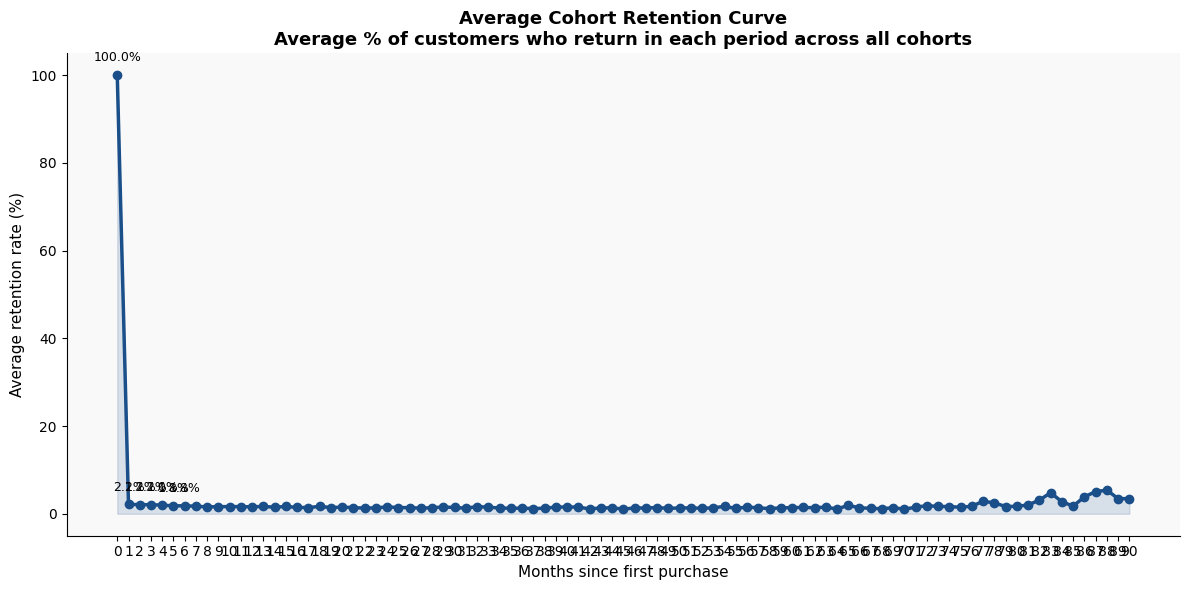

Period 0 (first purchase)  : 100.0% (baseline — 100% by definition)
Period 1 (month 2)         : 2.1%  →  97.9pp drop-off in first month
Period 3 (month 4)         : 2.1%


In [4]:
avg_retention = cohort_df.groupby('period_number')['retention_rate'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(avg_retention['period_number'], avg_retention['retention_rate'],
        color=BLUE, lw=2.5, marker='o', markersize=6)
ax.fill_between(avg_retention['period_number'], avg_retention['retention_rate'],
                alpha=0.15, color=BLUE)

ax.set_title('Average Cohort Retention Curve\n'
             'Average % of customers who return in each period across all cohorts',
             fontweight='bold')
ax.set_xlabel('Months since first purchase')
ax.set_ylabel('Average retention rate (%)')
ax.set_xticks(avg_retention['period_number'])

for _, row in avg_retention[avg_retention['period_number'] <= 6].iterrows():
    ax.annotate(f"{row['retention_rate']:.1f}%",
                (row['period_number'], row['retention_rate']),
                textcoords='offset points', xytext=(0, 10),
                ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / '06_avg_retention_curve.png', dpi=150, bbox_inches='tight')
plt.show()

p0 = avg_retention[avg_retention['period_number'] == 0]['retention_rate'].values[0]
p1 = avg_retention[avg_retention['period_number'] == 1]['retention_rate'].values[0]
p3 = avg_retention[avg_retention['period_number'] == 3]['retention_rate'].values[0] if 3 in avg_retention['period_number'].values else None

print(f"Period 0 (first purchase)  : {p0:.1f}% (baseline — 100% by definition)")
print(f"Period 1 (month 2)         : {p1:.1f}%  →  {p0-p1:.1f}pp drop-off in first month")
if p3:
    print(f"Period 3 (month 4)         : {p3:.1f}%")


New vs returning customers per month

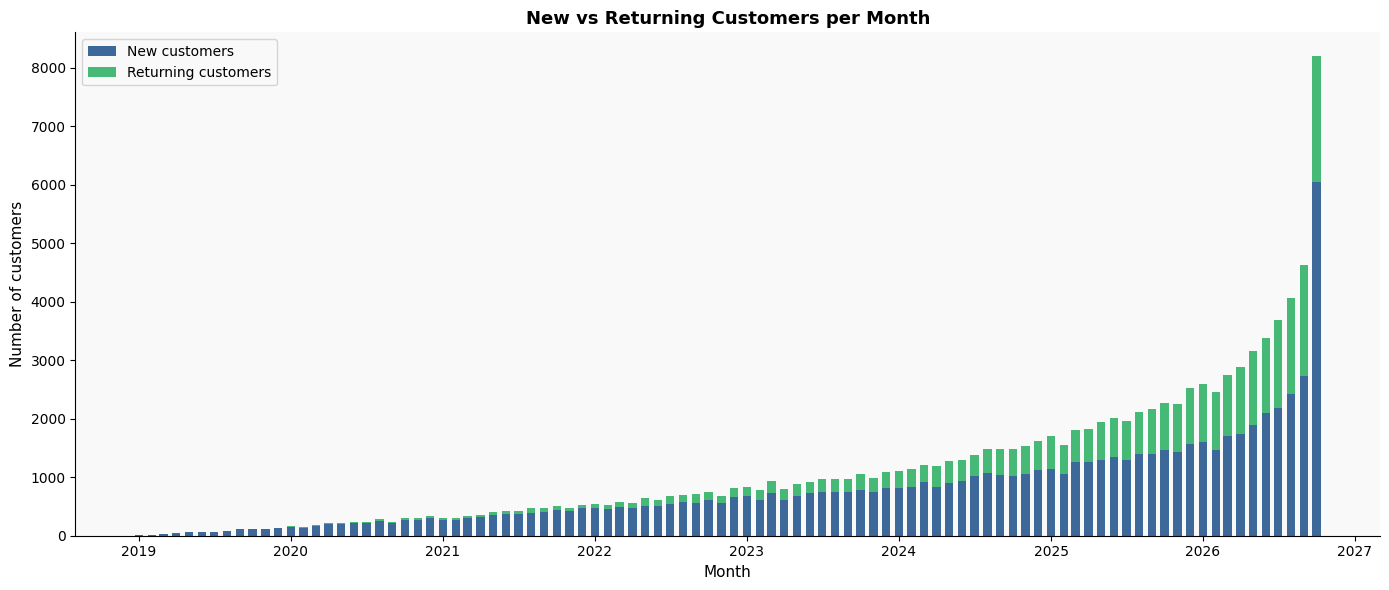

In [5]:
new_returning_sql = f"""
WITH first_orders AS (
    SELECT user_id, MIN(DATE_TRUNC(created_at, MONTH)) AS first_month
    FROM `{DATASET}.orders`
    WHERE status NOT IN ('Cancelled')
    GROUP BY user_id
)
SELECT
    DATE_TRUNC(o.created_at, MONTH)                        AS month,
    COUNTIF(DATE_TRUNC(o.created_at, MONTH) = fo.first_month) AS new_customers,
    COUNTIF(DATE_TRUNC(o.created_at, MONTH) > fo.first_month)  AS returning_customers
FROM `{DATASET}.orders` o
JOIN first_orders fo ON o.user_id = fo.user_id
WHERE o.status NOT IN ('Cancelled')
GROUP BY 1
ORDER BY 1
"""
nr_df = run_query(new_returning_sql)
nr_df['month'] = pd.to_datetime(nr_df['month'])

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(nr_df['month'], nr_df['new_customers'],
       label='New customers', color=BLUE, alpha=0.85, width=20)
ax.bar(nr_df['month'], nr_df['returning_customers'],
       bottom=nr_df['new_customers'],
       label='Returning customers', color=GREEN, alpha=0.85, width=20)
ax.set_title('New vs Returning Customers per Month', fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Number of customers')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / '07_new_vs_returning.png', dpi=150, bbox_inches='tight')
plt.show()

nr_df.to_csv(PROCESSED / 'new_vs_returning.csv', index=False)


Explore the events table

In [6]:
print("=" * 65)
print("SECTION 2: CONVERSION FUNNEL ANALYSIS")
print("=" * 65)

event_types_sql = f"""
SELECT
    event_type,
    COUNT(*)                                              AS events,
    COUNT(DISTINCT user_id)                               AS unique_users,
    COUNT(DISTINCT session_id)                            AS unique_sessions
FROM `{DATASET}.events`
GROUP BY 1
ORDER BY events DESC
"""
event_types = run_query(event_types_sql)
print("Event types in the dataset:")
print(event_types.to_string(index=False))


SECTION 2: CONVERSION FUNNEL ANALYSIS
Event types in the dataset:
event_type  events  unique_users  unique_sessions
   product  843442         79748           680746
department  593797         79748           431101
      cart  592282         79748           429586
  purchase  180746         79748           180746
    cancel  124483             0           124483
      home   86957         62569            86957


Conversion funnel: browse → cart → purchase

In [7]:
funnel_sql = f"""
WITH session_events AS (
    SELECT
        session_id,
        user_id,
        MAX(CASE WHEN event_type = 'home'     THEN 1 ELSE 0 END) AS visited_home,
        MAX(CASE WHEN event_type = 'category' THEN 1 ELSE 0 END) AS browsed_category,
        MAX(CASE WHEN event_type = 'product'  THEN 1 ELSE 0 END) AS viewed_product,
        MAX(CASE WHEN event_type = 'cart'     THEN 1 ELSE 0 END) AS added_to_cart,
        MAX(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END) AS purchased
    FROM `{DATASET}.events`
    GROUP BY session_id, user_id
)
SELECT
    COUNT(*)                               AS total_sessions,
    SUM(visited_home)                      AS visited_home,
    SUM(browsed_category)                  AS browsed_category,
    SUM(viewed_product)                    AS viewed_product,
    SUM(added_to_cart)                     AS added_to_cart,
    SUM(purchased)                         AS purchased
FROM session_events
"""
funnel_raw = run_query(funnel_sql).iloc[0]

funnel_stages = ['Total Sessions', 'Visited Home',
                 'Browsed Category', 'Viewed Product',
                 'Added to Cart', 'Purchased']
funnel_values = [
    funnel_raw['total_sessions'],
    funnel_raw['visited_home'],
    funnel_raw['browsed_category'],
    funnel_raw['viewed_product'],
    funnel_raw['added_to_cart'],
    funnel_raw['purchased'],
]

top = funnel_values[0]
print("Conversion Funnel:")
print()
for i, (stage, val) in enumerate(zip(funnel_stages, funnel_values)):
    pct_top  = val / top * 100
    pct_prev = val / funnel_values[i-1] * 100 if i > 0 else 100.0
    drop     = 100 - pct_prev if i > 0 else 0
    bar      = '█' * int(pct_top / 2)
    print(f"  {stage:<22} {int(val):>8,}  ({pct_top:5.1f}% of top)  "
          f"drop-off: {drop:5.1f}%  {bar}")


Conversion Funnel:

  Total Sessions          680,746  (100.0% of top)  drop-off:   0.0%  ██████████████████████████████████████████████████
  Visited Home             86,957  ( 12.8% of top)  drop-off:  87.2%  ██████
  Browsed Category              0  (  0.0% of top)  drop-off: 100.0%  
  Viewed Product          680,746  (100.0% of top)  drop-off:  -inf%  ██████████████████████████████████████████████████
  Added to Cart           429,586  ( 63.1% of top)  drop-off:  36.9%  ███████████████████████████████
  Purchased               180,746  ( 26.6% of top)  drop-off:  57.9%  █████████████


Visualise funnel

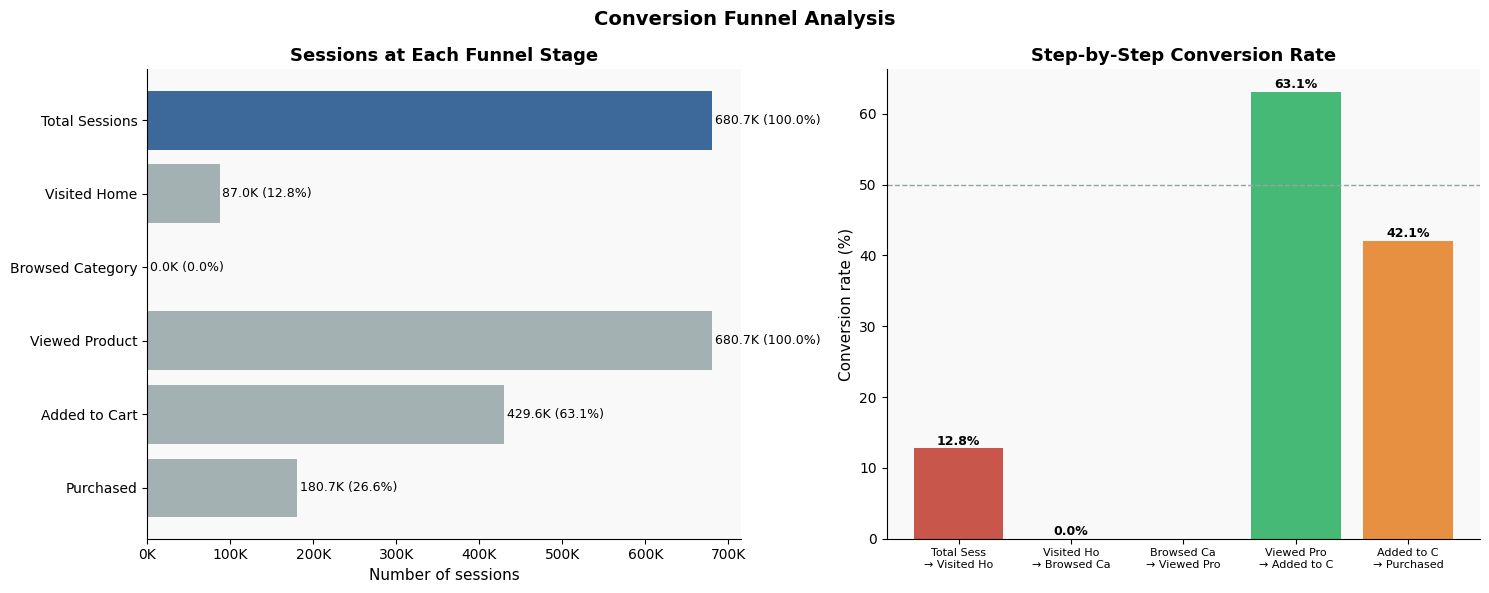

Saved: conversion_funnel.csv


In [8]:
pct_of_top = [v / top * 100 for v in funnel_values]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Conversion Funnel Analysis', fontsize=14, fontweight='bold')

# Left: volume funnel
colors = [BLUE if i == 0 else GREY for i in range(len(funnel_stages))]
axes[0].barh(funnel_stages[::-1], funnel_values[::-1],
             color=colors[::-1], alpha=0.85)
axes[0].set_title('Sessions at Each Funnel Stage', fontweight='bold')
axes[0].set_xlabel('Number of sessions')
axes[0].xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, _: f'{v/1000:.0f}K'))
for i, (stage, val) in enumerate(zip(reversed(funnel_stages), reversed(funnel_values))):
    axes[0].text(val + top * 0.005, i,
                 f'{val/1000:.1f}K ({val/top*100:.1f}%)',
                 va='center', fontsize=9)

# Right: step-by-step conversion rate
step_rates = [funnel_values[i] / funnel_values[i-1] * 100
              for i in range(1, len(funnel_values))]
step_labels = [f'{funnel_stages[i-1][:10]}\n→ {funnel_stages[i][:10]}'
               for i in range(1, len(funnel_stages))]

bar_colors = [GREEN if r >= 50 else ORANGE if r >= 25 else RED for r in step_rates]
axes[1].bar(range(len(step_rates)), step_rates,
            color=bar_colors, alpha=0.85)
axes[1].set_xticks(range(len(step_rates)))
axes[1].set_xticklabels(step_labels, fontsize=8)
axes[1].set_title('Step-by-Step Conversion Rate', fontweight='bold')
axes[1].set_ylabel('Conversion rate (%)')
axes[1].axhline(50, color=GREY, lw=1, linestyle='--', label='50% reference')
for i, r in enumerate(step_rates):
    axes[1].text(i, r + 0.5, f'{r:.1f}%', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(FIGURES / '08_conversion_funnel.png', dpi=150, bbox_inches='tight')
plt.show()

# Save
funnel_df = pd.DataFrame({'stage': funnel_stages, 'sessions': funnel_values,
                           'pct_of_top': pct_of_top})
funnel_df.to_csv(PROCESSED / 'conversion_funnel.csv', index=False)
print("Saved: conversion_funnel.csv")


Funnel by traffic source

In [9]:
funnel_by_source_sql = f"""
WITH session_events AS (
    SELECT
        session_id,
        MAX(traffic_source)                                AS traffic_source,
        MAX(CASE WHEN event_type = 'product'  THEN 1 ELSE 0 END) AS viewed_product,
        MAX(CASE WHEN event_type = 'cart'     THEN 1 ELSE 0 END) AS added_to_cart,
        MAX(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END) AS purchased
    FROM `{DATASET}.events`
    GROUP BY session_id
)
SELECT
    traffic_source,
    COUNT(*)                                                AS sessions,
    ROUND(SUM(viewed_product)  / COUNT(*) * 100, 2)        AS product_view_rate,
    ROUND(SUM(added_to_cart)   / COUNT(*) * 100, 2)        AS add_to_cart_rate,
    ROUND(SUM(purchased)       / COUNT(*) * 100, 2)        AS purchase_rate,
    ROUND(SUM(purchased) /
          NULLIF(SUM(added_to_cart), 0) * 100, 2)          AS cart_to_purchase_rate
FROM session_events
WHERE traffic_source IS NOT NULL
GROUP BY 1
ORDER BY sessions DESC
"""
source_df = run_query(funnel_by_source_sql)
print("Funnel metrics by traffic source:")
print(source_df.to_string(index=False))

source_df.to_csv(PROCESSED / 'funnel_by_source.csv', index=False)


Funnel metrics by traffic source:
traffic_source  sessions  product_view_rate  add_to_cart_rate  purchase_rate  cart_to_purchase_rate
         Email    306823              100.0             63.14          26.54                  42.03
       Adwords    203654              100.0             63.15          26.57                  42.07
      Facebook     68179              100.0             62.61          26.30                  42.00
       YouTube     68091              100.0             63.22          26.61                  42.08
       Organic     33999              100.0             63.28          26.98                  42.64


Time-to-purchase: how long does conversion take?

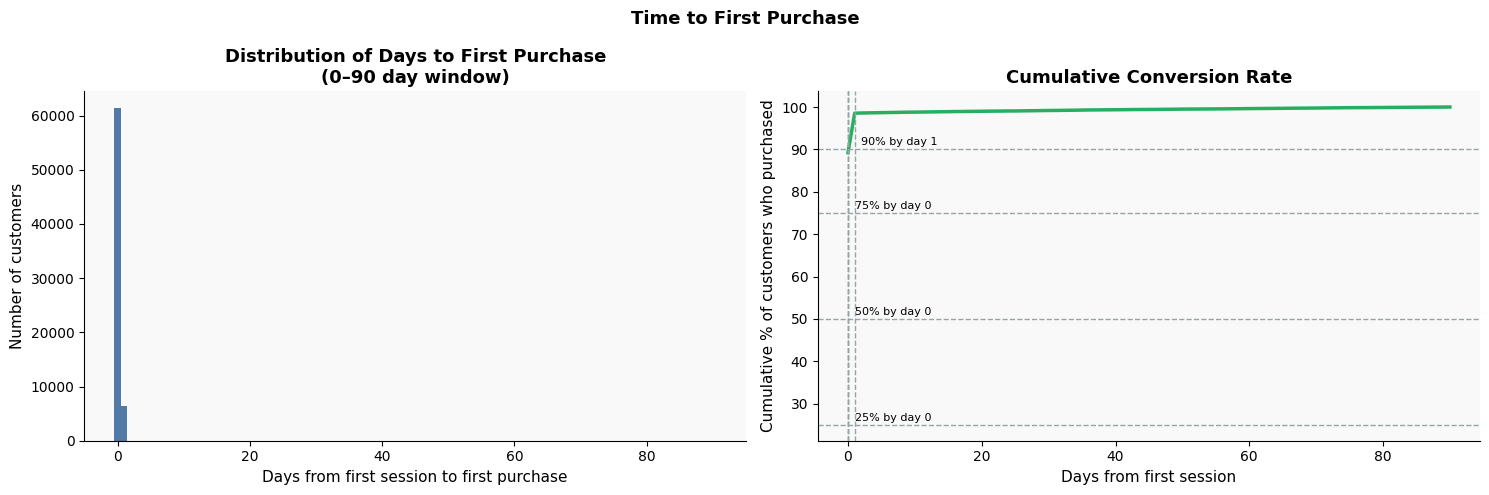

Saved: time_to_purchase.csv


In [10]:
ttp_sql = f"""
WITH first_session AS (
    SELECT
        user_id,
        MIN(created_at) AS first_session_time
    FROM `{DATASET}.events`
    GROUP BY user_id
),
first_purchase AS (
    SELECT
        user_id,
        MIN(created_at) AS first_purchase_time
    FROM `{DATASET}.orders`
    WHERE status NOT IN ('Cancelled')
    GROUP BY user_id
)
SELECT
    DATE_DIFF(DATE(fp.first_purchase_time),
              DATE(fs.first_session_time), DAY) AS days_to_purchase,
    COUNT(*) AS customers
FROM first_session fs
JOIN first_purchase fp ON fs.user_id = fp.user_id
WHERE DATE_DIFF(DATE(fp.first_purchase_time),
                DATE(fs.first_session_time), DAY) BETWEEN 0 AND 90
GROUP BY 1
ORDER BY 1
"""
ttp_df = run_query(ttp_sql)

cumulative = ttp_df['customers'].cumsum() / ttp_df['customers'].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Time to First Purchase', fontsize=13, fontweight='bold')

axes[0].bar(ttp_df['days_to_purchase'], ttp_df['customers'],
            color=BLUE, alpha=0.75, width=1)
axes[0].set_title('Distribution of Days to First Purchase\n(0–90 day window)',
                  fontweight='bold')
axes[0].set_xlabel('Days from first session to first purchase')
axes[0].set_ylabel('Number of customers')

axes[1].plot(ttp_df['days_to_purchase'], cumulative,
             color=GREEN, lw=2.5)
for pct in [25, 50, 75, 90]:
    idx = (cumulative >= pct).idxmax()
    d   = ttp_df.loc[idx, 'days_to_purchase']
    axes[1].axhline(pct, color=GREY, lw=1, linestyle='--')
    axes[1].axvline(d,   color=GREY, lw=1, linestyle='--')
    axes[1].text(d + 1, pct + 1, f'{pct}% by day {d}', fontsize=8)
axes[1].set_title('Cumulative Conversion Rate', fontweight='bold')
axes[1].set_xlabel('Days from first session')
axes[1].set_ylabel('Cumulative % of customers who purchased')

plt.tight_layout()
plt.savefig(FIGURES / '09_time_to_purchase.png', dpi=150, bbox_inches='tight')
plt.show()

ttp_df.to_csv(PROCESSED / 'time_to_purchase.csv', index=False)
print("Saved: time_to_purchase.csv")
